In [3]:
import torch
import numpy as np
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import torchvision
import tqdm
import glob
from PIL import Image
import seaborn as sns

import sys
sys.path.append('../../vision')

import datasets
import training_loop
import losses
import models

if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')
print(device)

cuda


In [18]:
# quality_label_df = pd.concat((pd.read_csv('../../labels/me_4_ch_cycle_04_complete_EJM.csv'), 
#                               pd.read_csv('../../labels/me_4_ch_cycle_05_complete_EJM.csv'), 
#                               pd.read_csv('../../labels/me_4_ch_cycle_06_complete_EJM.csv')))
# quality_label_df.drop(columns='Unnamed: 4').reset_index().to_csv('../../labels/quality_grading_300.csv')

quality_label_df = pd.read_csv('../../labels/quality_grading_300.csv')

In [19]:
class QualityDataset(torch.utils.data.Dataset):

    def __init__(self, labels_df, transform=None, duration=32, skip=1):
        self.labels_df = labels_df
        self.transform = transform
        self.duration = duration
        self.skip = skip

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, idx):                  
        label = torch.tensor((self.labels_df.iloc[idx]['LV'] == 'y' , self.labels_df.iloc[idx]['RV'] == 'y'))
        
        data = self.__read_images(self.labels_df.iloc[idx]['clip_path'], self.duration, self.skip)
        
        if self.transform:
            data = self.transform(data)
            
        data = data.permute(1,0,2,3) # reshape to (C,T,H,W)
            
        return {'data':data, 'label':label}
    
    
    def __read_images(self, path, duration=32, skip=1):
        frame_paths = glob.glob(path+'/*')
        if len(frame_paths) <= duration * skip:
            start = 0
            stop = len(frame_paths)
            pad = (duration * skip - stop) // skip
        else:
            start = np.random.randint(0, len(frame_paths) - duration * skip + 1)
            stop = start + duration * skip
            pad = 0
        frames = []
        for frame in sorted(frame_paths)[start:stop:skip]:
            frames.append(torchvision.transforms.functional.to_tensor((Image.open(frame))))
        for i in range(pad):
            frames.append(torch.zeros_like(frames[-1]))
        frames = torch.stack(frames, dim=0)
        return frames
    
# plt.imshow(train_dataset[0]['data'][:,0].permute(1,2,0))

In [20]:
# train_transforms = datasets.TransformsComposed('train', size=(224,224))
train_transforms = datasets.TransformsComposed('valtest', size=(224,224))
valtest_transforms = datasets.TransformsComposed('valtest', size=(224,224))

In [21]:
train_dataset = QualityDataset(quality_label_df[:1000], transform=train_transforms, duration=32, skip=1)
test_dataset = QualityDataset(quality_label_df[1000:], transform=valtest_transforms, duration=32, skip=1)

In [22]:
model = models.fetch_s3d_model(
    num_classes = 2,
    dropout = 0.2,
).to(device)

In [23]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, betas=(0.9, 0.999), eps=1e-08, weight_decay=0,)

In [24]:
class SimpleLoss:
    def __init__(self,):
        self.mse = torch.nn.MSELoss()

    def __call__(self, net, data, label):
        x = data
        y = net(x).squeeze()
        label = label.squeeze()
        assert y.shape == label.shape, "mismatched dimensions in model output"
        # loss = ((y - label) ** 2)
        loss = self.mse(y, label)
        # loss[torch.isnan(loss)] = 0
        # print(label)
        # print(y)
        return loss
    
loss_fn = SimpleLoss()

In [8]:
import torch
import numpy as np
import os
import time
import copy
import json
import pickle
import datasets
import matplotlib.pyplot as plt

def collate_fn(batch):
  return {
      'data': torch.stack([x['data'] for x in batch], dim=0),
      'label': torch.stack([x['label'] for x in batch], dim=0),
}

def simple_training_loop(
    run_dir             = '.',      # Output directory.
    dataset             = None,     # Training dataset
    validation_dataset  = None,     # Validation dataset
    network             = None,     # Options for model and preconditioning.
    loss                = None,     # Options for loss function.
    optimizer           = None,     # Options for optimizer.
    seed                = 0,        # Global random seed.
    batch_size          = 32,       # Total batch size for one training iteration.
    num_workers         = 8,        # Number of data loading workers.
    total_kimg          = 200000,   # Training duration, measured in thousands of training images.
    device              = torch.device('cuda'),
    kimg_per_tick       = 100,      # How often to log training and validation stats.
    kimg_per_save       = 1000,     # How often to save the training state.
    val_length          = 10,       # How many data parcels to run validation on (more takes longer)
):
    # Initialize.
    start_time = time.time()
    if os.path.isdir(run_dir):
        # raise RuntimeError(f'Output directory "{run_dir}" already exists')
        os.makedirs(run_dir, exist_ok=True)
    else:
        os.makedirs(run_dir, exist_ok=True)

    # Load dataset.
    print('Loading dataset...')
    dataset_obj = dataset
    dataset_sampler = iter(datasets.InfiniteSampler(dataset=dataset_obj, rank=0, num_replicas=1, shuffle=True, seed=seed, window_size=0.5))
    dataset_iterator = iter(torch.utils.data.DataLoader(dataset=dataset_obj, batch_size=batch_size, num_workers=num_workers, sampler=dataset_sampler, collate_fn=collate_fn))
    if validation_dataset:
        val_dataset_obj = validation_dataset
        val_dataset_sampler = iter(datasets.InfiniteSampler(dataset=val_dataset_obj, rank=0, num_replicas=1, shuffle=True, seed=seed, window_size=0.5))
        val_dataset_iterator = iter(torch.utils.data.DataLoader(dataset=val_dataset_obj, batch_size=batch_size, num_workers=1, sampler=val_dataset_sampler, collate_fn=collate_fn))


    # Construct network.
    print('Constructing network...')
    net = network
    net.train().requires_grad_(True).to(device)

    # Setup optimizer.
    print('Setting up optimizer...')
    loss_fn = loss
    optimizer = optimizer
    
    # Setup logs.
    print('Setting up logs...')
    running_loss = []
    training_stats = dict(
        tick = [],
        tick_start_time = [],
        tick_runtime = [],
        loss = [],
        std = [],
        valloss = [],
        valstd = [],
    )

    # Train.
    print(f'Training for {total_kimg} kimg...')
    print()
    cur_nimg = 0
    cur_tick = 0
    cur_save = 1
    tick_start_nimg = cur_nimg
    tick_start_time = time.time()
    # dist.update_progress(cur_nimg // 1000, total_kimg)
    
    while True:
        
        # Accumulate gradients.
        optimizer.zero_grad(set_to_none=True)
        
        parcel = next(dataset_iterator)
        data = parcel['data']
        label = parcel['label']
        data = data.to(device).to(torch.float32)
        label = label.to(device).to(torch.float32)
        loss = loss_fn(net=net, data=data, label=label)
        running_loss.append(loss)
        loss.sum().backward()
        
        
        # print(f'data : {data.shape}')
        # print(f'label : {label}')
        # print(f'loss : {loss}')
        # print(f'image : {parcel["acc"]}')
        # if cur_nimg % 100 == 0:
        #     plt.imshow(data[0,:,0,:,:].permute(1,2,0).cpu())

        # Update weights.
        for param in net.parameters():
            if param.grad is not None:
                torch.nan_to_num(param.grad, nan=0, posinf=1e5, neginf=-1e5, out=param.grad)
        optimizer.step()

        # Perform maintenance tasks once per tick.
        cur_tick += 1
        cur_nimg += batch_size
        done = (cur_nimg >= total_kimg * 1000)
        if (not done) and (cur_tick != 0) and (cur_nimg < tick_start_nimg + kimg_per_tick * 1000):
            continue
        
        # Save full dump of the training state.
        if (not done) and (cur_tick != 0) and (cur_nimg > (cur_save) * kimg_per_save * 1000):
            cur_save += 1
            torch.save(dict(net=net, optimizer_state=optimizer.state_dict()), os.path.join(run_dir, f'training-state-{cur_nimg//1000:06d}.pt'))
            print(f'saved to training-state-{cur_nimg//1000:06d}.pt')
        
        # Validation
        if validation_dataset:
            model.eval()
            with torch.no_grad():
                val_loss = []
                for idx in range(val_length):
                    parcel = next(val_dataset_iterator)
                    data = parcel['data']
                    label = parcel['label']
                    data = data.to(device).to(torch.float32)
                    label = label.to(device).to(torch.float32)
                    loss = loss_fn(net=net, data=data, label=label)
                    val_loss.append(loss)
                training_stats['valloss'].append(torch.mean(torch.stack(val_loss)).item())
                training_stats['valstd'].append(torch.std(torch.stack(val_loss)).item())
            model.train()
                
        # Update logs.
        training_stats['tick'].append(cur_tick)
        training_stats['tick_start_time'].append(tick_start_time)
        training_stats['tick_runtime'].append(time.time() - tick_start_time)
        training_stats['loss'].append(torch.mean(torch.stack(running_loss)).item())
        training_stats['std'].append(torch.std(torch.stack(running_loss)).item())
        json.dump(training_stats, open(os.path.join(run_dir, 'log.json'), 'wt'))
        running_loss = []
        if validation_dataset:
            print(f"tick {cur_tick}, loss {training_stats['loss'][-1]:.4f}, std {training_stats['std'][-1]:.4f}, valloss {training_stats['valloss'][-1]:.4f}, valstd {training_stats['valstd'][-1]:.4f}, time {training_stats['tick_runtime'][-1]:.2f} sec")
        else:
            print(f"tick {cur_tick}, loss {training_stats['loss'][-1]:.4f}, std {training_stats['std'][-1]:.4f}, time {training_stats['tick_runtime'][-1]:.2f} sec")

        # Update state.
        tick_start_nimg = cur_nimg
        tick_start_time = time.time()
        if done:
            break

    # Done.
    print()
    print('Exiting...')

#----------------------------------------------------------------------------

In [11]:
# model = torch.load('/home/trevor/repos/deep_TEE/experiments/quality_pred_s3d_224_16_1_0/training-state-000120.pt')['net'].to(device)

In [13]:
simple_training_loop(
    run_dir             = '../experiments/quality_pred_s3d_224_16_1_1',  # Output directory.
    dataset             = train_dataset,                # Options for training set.
    validation_dataset  = test_dataset,                 # Options for training set.
    network             = model,                        # Options for model and preconditioning.
    loss                = loss_fn,                      # Options for loss function.
    optimizer           = optimizer,                    # Options for optimizer.
    seed                = 0,                            # Global random seed.
    batch_size          = 16,                           # Total batch size for one training iteration.
    num_workers         = 8,                            # Number of data loading workers.
    total_kimg          = 1000,                          # Training duration, measured in thousands of training images.
    kimg_per_tick       = 5,                           # How often to log training and validation stats.
    kimg_per_save       = 10,                           # How often to save the training state.
    device              = torch.device('cuda'),
)

Loading dataset...
Constructing network...
Setting up optimizer...
Setting up logs...
Training for 1000 kimg...

tick 313, loss 0.0137, std 0.0134, valloss 0.1877, valstd 0.0600, time 95.51 sec
saved to training-state-000010.pt
tick 626, loss 0.0090, std 0.0117, valloss 0.2382, valstd 0.0783, time 95.00 sec
tick 939, loss 0.0066, std 0.0089, valloss 0.1973, valstd 0.0488, time 95.14 sec
saved to training-state-000020.pt
tick 1252, loss 0.0055, std 0.0081, valloss 0.2008, valstd 0.0748, time 95.73 sec
tick 1565, loss 0.0099, std 0.0106, valloss 0.2033, valstd 0.0771, time 94.85 sec
saved to training-state-000030.pt
tick 1878, loss 0.0046, std 0.0069, valloss 0.1716, valstd 0.0703, time 95.56 sec
tick 2191, loss 0.0094, std 0.0132, valloss 0.2141, valstd 0.0643, time 94.84 sec
saved to training-state-000040.pt
tick 2504, loss 0.0075, std 0.0104, valloss 0.1810, valstd 0.0439, time 95.00 sec
tick 2817, loss 0.0080, std 0.0112, valloss 0.2043, valstd 0.0541, time 94.77 sec
saved to trainin

KeyboardInterrupt: 

In [6]:
model = torch.load('/home/trevor/repos/deep_TEE/experiments/quality_pred_s3d_224_16_1_1/training-state-000270.pt')['net'].to(device)
model.eval()

S3D(
  (features): Sequential(
    (0): TemporalSeparableConv(
      (0): Conv3dNormActivation(
        (0): Conv3d(3, 64, kernel_size=(1, 7, 7), stride=(1, 2, 2), padding=(0, 3, 3), bias=False)
        (1): BatchNorm3d(64, eps=0.001, momentum=0.001, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (1): Conv3dNormActivation(
        (0): Conv3d(64, 64, kernel_size=(7, 1, 1), stride=(2, 1, 1), padding=(3, 0, 0), bias=False)
        (1): BatchNorm3d(64, eps=0.001, momentum=0.001, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (1): MaxPool3d(kernel_size=(1, 3, 3), stride=(1, 2, 2), padding=(0, 1, 1), dilation=1, ceil_mode=False)
    (2): Conv3dNormActivation(
      (0): Conv3d(64, 64, kernel_size=(1, 1, 1), stride=(1, 1, 1), bias=False)
      (1): BatchNorm3d(64, eps=0.001, momentum=0.001, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (3): TemporalSeparableConv(
      (0): Conv3d

In [7]:
yL = []
ypL = []
yR = []
ypR = []
maxsample = 200

with torch.no_grad():
    for idx in tqdm.tqdm(range(min(len(test_dataset), maxsample))):
        label = test_dataset[idx]['label']
        yL.append(label[0])
        yR.append(label[1])
        pred = model(test_dataset[idx]['data'].unsqueeze(0).to(device))[0]
        ypL.append(pred[0].item())
        ypR.append(pred[1].item())
df = pd.DataFrame({'yL':[v.item() for v in yL], 'ypL':ypL, 'yR':[v.item() for v in yR], 'ypR':ypR})

100%|██████████| 200/200 [00:12<00:00, 16.36it/s]


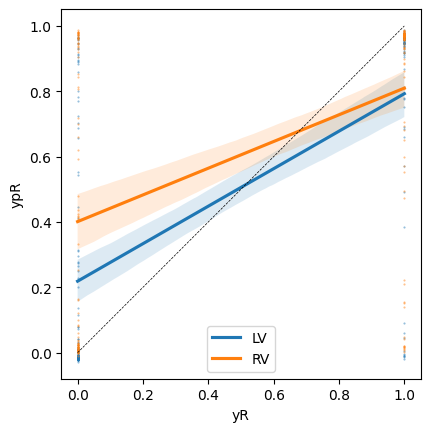

In [8]:
fig, ax = plt.subplots(1,1)
ax = sns.regplot(data=df, x="yL", y="ypL", marker='.', ax=ax, scatter_kws={'alpha':0.5, 's':1}, line_kws={'label':'LV'})
ax = sns.regplot(data=df, x="yR", y="ypR", marker='.', ax=ax, scatter_kws={'alpha':0.5, 's':1}, line_kws={'label':'RV'})
ax.plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax.set_aspect('equal')

plt.legend()

Logistic: ROC AUC=0.872
Logistic: ROC AUC=0.773


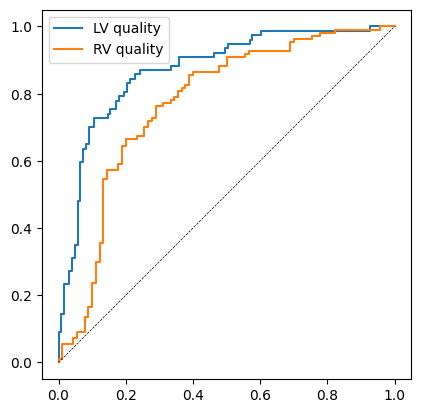

In [9]:
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
l_auc = roc_auc_score(yL, ypL)
r_auc = roc_auc_score(yR, ypR)
print('Logistic: ROC AUC=%.3f' % (l_auc))
print('Logistic: ROC AUC=%.3f' % (r_auc))
l_fpr, l_tpr, _ = roc_curve(yL, ypL)
r_fpr, r_tpr, _ = roc_curve(yR, ypR)
plt.plot(l_fpr, l_tpr, label='LV quality')
plt.plot(r_fpr, r_tpr, label='RV quality')

plt.plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
plt.legend()
plt.gca().set_aspect('equal')

Logistic: ROC AUC=0.872


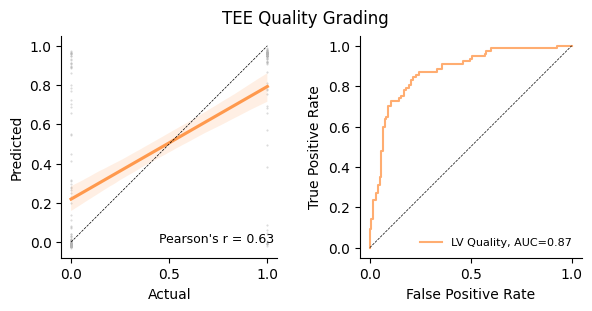

In [12]:
fig, ax = plt.subplots(1,2, figsize=(6,3), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])

y, yp = yL, ypL

from scipy import stats
res = stats.pearsonr(y, yp)
sns.regplot(data=df, x="yL", y="ypL", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


y50 = [v > 0.5 for v in y]
y25 = [v > 0.25 for v in y]

testy, predy = y50, yp
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[1].plot(fpr, tpr, label='LV Quality, AUC={:.2f}'.format(auc), c=[1, 0.6, 0.3], alpha=0.8, lw=1.5)

ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].legend(fontsize=8, frameon=False)
ax[1].set_ylabel('True Positive Rate')
ax[1].set_xlabel('False Positive Rate')

plt.suptitle('TEE Quality Grading')
# ax[1].set_title('TEE Quality Grading\n')

plt.savefig('LV_QualityGrading.png',dpi=300)

In [ ]:
class EvaluationDataset(torch.utils.data.Dataset):

    def __init__(self, clips, transform=None, duration=32, skip=1, autobatch=True):
        self.clips = clips
        self.transform = transform
        self.duration = duration
        self.skip = skip
        self.autobatch = autobatch

    def __len__(self):
        return len(self.clips)

    def __getitem__(self, idx):                          
        data = self.__read_images(self.clips[idx], self.duration, self.skip)
        
        if self.transform:
            data = self.transform(data)
            
        data = data.permute(0,2,1,3,4) # reshape to (B,C,T,H,W)
            
        return {'data':data}
    
    def __read_images(self, path, duration=32, skip=1):
        frame_paths = glob.glob(path+'/*')
        if not self.autobatch:
            if len(frame_paths) <= duration * skip:
                start = 0
                stop = len(frame_paths)
                pad = (duration * skip - stop) // skip
            else:
                start = np.random.randint(0, len(frame_paths) - duration * skip + 1)
                stop = start + duration * skip
                pad = 0
            frames = []
            for frame in sorted(frame_paths)[start:stop:skip]:
                frames.append(torchvision.transforms.functional.to_tensor((Image.open(frame))))
            for i in range(pad):
                frames.append(torch.zeros_like(frames[-1]))
            frames = torch.stack(frames, dim=0)
            batches = frames
        else:
            batches = []
            for batch in range(int(np.ceil(len(frame_paths)/skip/duration))):
                start = batch * skip * duration
                stop = min((batch + 1) * skip * duration, len(frame_paths))
                pad = min(0, len(frame_paths) - ((batch + 1) * skip * duration))
                frames = []
                for frame in sorted(frame_paths)[start:stop:skip]:
                    frames.append(torchvision.transforms.functional.to_tensor((Image.open(frame))))
                for i in range(-pad):
                    frames.append(torch.zeros_like(frames[-1]))
                frames = torch.stack(frames, dim=0)
                batches.append(frames)
            batches = torch.stack(batches, dim=0)
        return batches

In [ ]:
clips = glob.glob('/home/trevor/repos/deep_TEE/data/semi-processed/unsupervised/train/*/*')

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(6,3), layout="constrained")
for a in ax:
    a.spines[['right', 'top']].set_visible(False)
    a.set_aspect('equal')
    a.set_xticks([0,0.5,1])

from scipy import stats
res = stats.pearsonr(y, yp)
sns.regplot(data=df, x="y", y="yp", marker='.', ax=ax[0], scatter_kws={'alpha':0.5, 's':1, 'color':[0.7, 0.7, 0.7]}, line_kws={'label':'LV EF, (r={:.2f}, p={:.2f})'.format(res[0],res[1]),'color':[1, 0.6, 0.3]})
ax[0].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[0].set_aspect('equal')
ax[0].set_ylabel('Predicted')
ax[0].set_xlabel('Actual')
ax[0].text(0.45,0,"Pearson's r = {:.2f}".format(res[0]), fontsize=9)


y50 = [v > 0.5 for v in y]
y25 = [v > 0.25 for v in y]

testy, predy = y50, yp
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[1].plot(fpr, tpr, label='LV EF > 50%, AUC={:.2f}'.format(auc), c=[1,0.4,0.4], alpha=0.8, lw=1.5)

testy, predy = y25, yp
auc = roc_auc_score(testy, predy)
print('Logistic: ROC AUC=%.3f' % (auc))
fpr, tpr, _ = roc_curve(testy, predy)
ax[1].plot(fpr, tpr, label='LV EF > 25%, AUC={:.2f}'.format(auc), c=[0.5,0.9,0.8], alpha=0.8, lw=1.5)

ax[1].plot([0,1], [0,1], color='k', linestyle='--', lw=0.5)
ax[1].legend(fontsize=8, frameon=False)
ax[1].set_ylabel('True Positive Rate')
ax[1].set_xlabel('False Positive Rate')

# plt.suptitle('Predicting Left Ventricular Ejection Fraction')
ax[1].set_title('Predicting Left Ventricular\nEjection Fraction')